In [148]:
# ===============================
# import libraries
# ===============================
import numpy as np
import pandas as pd
from pathlib import Path
import chartgazing as cg

cg.set_size("4:5")

In [ ]:
# ===============================
# import card data
# ===============================

# set data directory
DATA_DIR = Path("data/sets")

# combine every saved set
pokemon_all = pd.concat(
    [pd.read_csv(path, dtype={"number": str, "product_id": str, "variant": str}, parse_dates=["date"]) for path in DATA_DIR.glob("*.csv")],
    ignore_index=True
)

# additional data on each set
sets_df = pd.read_csv("data/sets_info.csv", parse_dates=["release_date"])
pokemon_all = pokemon_all.merge(sets_df, on="set_slug", how="left")

In [ ]:
# ===============================
# clean data
# ===============================
pokemon_all["variant"] = pokemon_all["variant"].fillna("Standard")
pokemon_all["price"] = pokemon_all["price"].replace(0, np.nan)
pokemon_all["date"] = pokemon_all["date"].dt.to_period("M").dt.to_timestamp()
pokemon_all["decade"] = (pokemon_all["release_date"].dt.year // 10) * 10


for col in ["grade", "set_slug", "set_name", "language", "name", "variant"]:
    pokemon_all[col] = pokemon_all[col].astype("category")

In [ ]:
# ===============================
# Changes for all cards
# ===============================
GRADE = "Ungraded"
IMAGE_DIR = "images/4x5"
source = "Source: PriceCharting.com"

all_prices = pokemon_all.dropna(subset=["price"])

# TEMP LINE
# priced_cards = all_prices[all_prices["grade"] == GRADE]
priced_cards = all_prices

latest_date = priced_cards["date"].max()
latest_cards = priced_cards[priced_cards["date"] == latest_date]

def fmt(value):
    return f"${value:,.0f}" if value >= 1000 else f"${value:.2f}"

def short_set(set_name):
    return set_name.removeprefix("Pokemon ")

def one_per_card(cards):
    return(
        cards.assign(not_standard=cards["variant"] != "Standard")
        .sort_values(["not_standard", "price"])
        .drop_duplicates(["set_slug", "number", "name"])
    )

In [ ]:
# ===============================
# prepare 2026 card price change
# ===============================
cards_2026 = all_prices.assign(date=all_prices["date"] - pd.DateOffset(months=1))
cards_2026 = cards_2026[
    (cards_2026["date"] >= "2026-01-01")
    & (cards_2026["date"] <= "2026-08-01")
    & (cards_2026["grade"] == GRADE)
]

year_start = cards_2026.loc[cards_2026["date"] == "2026-01-01", "product_id"].unique()

print(cards_2026.shape)

cards_2026 = cards_2026[cards_2026["product_id"].isin(year_start)]

cards_26 = cards_2026.groupby("date", as_index=False).agg(
    unique_cards = ("product_id", "nunique"),
    mean_price = ("price", "mean")
)

cards_26["PK_pct_chng"] = ((cards_26["mean_price"] - cards_26["mean_price"].iloc[0]) / cards_26["mean_price"].iloc[0]) * 100

# ===============================
# import S&P 500 data
# ===============================
sp_500 = pd.read_csv(f"data/S&P_500.csv")

sp_500["Date"] = pd.to_datetime(sp_500["Date"], format="%d/%m/%Y")

sp_500["Change"] = sp_500["Change %"].str.removesuffix("%") 
sp_500 = sp_500[["Date", "Price", "Change"]]

sp_500["Change"] = sp_500["Change"].astype(float)
sp_500["Price"] = sp_500["Price"].str.replace(r"[^\d\.]", "",regex=True).astype(float)

sp_500 = sp_500[sp_500["Date"] >= "2026-01-01"]

sp_500 = sp_500.sort_values(by="Date", ascending=True)

sp_500["SP_pct_chng"] = ((sp_500["Price"] - sp_500["Price"].iloc[0]) / sp_500["Price"].iloc[0]) * 100

sp_500.columns = sp_500.columns.str.lower()


# ===============================
# combined 2026 returns
# ===============================

returns = pd.merge(cards_26, sp_500, on='date')

returns = returns[["date", "PK_pct_chng", "sp_pct_chng"]]

returns = returns.rename(columns={"PK_pct_chng": "Pokémon", "sp_pct_chng": "S&P500"})

returns = pd.melt(returns, id_vars="date", var_name="category", value_name="pct_change")

returns

(316128, 13)


,Date,Price,Open,High,Low,Vol.,Change %
0,2026-11-01,"7,376.86","7,610.83","7,715.57","7,350.35",NaN,-2.68%
1,2026-10-01,"7,580.07","7,666.47","7,844.52","7,527.56",NaN,-0.93%
2,2026-09-01,"7,651.54","7,635.47","7,782.19","7,507.77",NaN,-0.45%
3,2026-08-01,"7,686.14","7,504.78","7,816.70","7,504.78",NaN,2.62%
4,2026-07-01,"7,489.72","7,478.84","7,581.50","7,313.92",NaN,-0.13%
5,2026-06-01,"7,499.36","7,582.29","7,620.90","7,237.85",NaN,-1.06%
6,2026-05-01,"7,580.06","7,234.54","7,599.38","7,174.12",NaN,5.15%
7,2026-04-01,"7,209.01","6,556.56","7,219.83","6,474.94",NaN,10.42%
8,2026-03-01,"6,528.52","6,824.36","6,901.01","6,316.91",NaN,-5.09%
9,2026-02-01,"6,878.88","6,916.64","6,993.48","6,775.50",NaN,-0.87%


               date  pct_change
category                       
Pokémon  2026-08-01   37.856491
S&P500   2026-08-01   10.766779


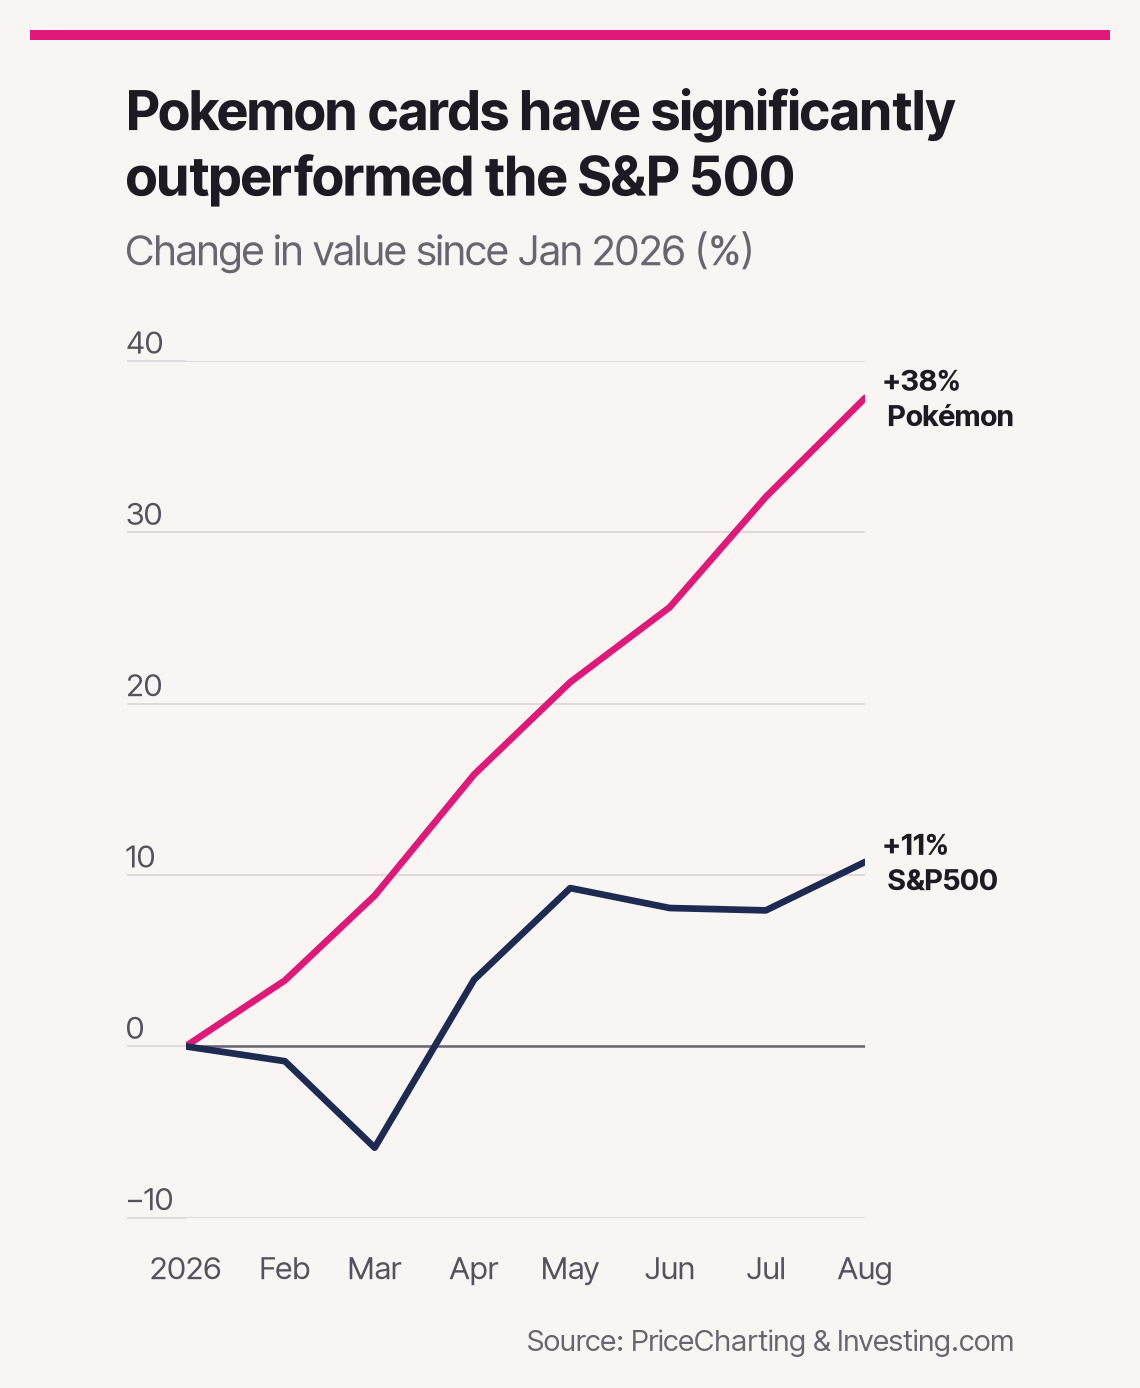

In [177]:
CHART_DIR = Path("charts/")

fig, ax = cg.line(returns, x="date", y="pct_change", group="category",
                  title="Pokemon cards have significantly outperformed the S&P 500",
                  subtitle="Change in value since Jan 2026 (%)",
                  source="Source: PriceCharting & Investing.com",
                  labels=False)

ax.set_yticks([-10, 0, 10, 20, 30, 40, 50])

last = returns.sort_values("date").groupby("category").last()

print(last)

cg.label_ends(ax, last["pct_change"].to_dict(), fmt=lambda name, value: f"+{value:.0f}% \n {name}")

cg.save(fig, CHART_DIR / "SP500.png")


In [ ]:
help(cg)

Help on package chartgazing:

NAME
    chartgazing - chartgazing — the house style.

DESCRIPTION
    Single chart:

        import chartgazing as cg

        fig, ax = cg.chart("Title", "Subtitle (units)", note="Note: ...", source="Source: ...")
        ax.plot(x, y, color=cg.PRIMARY)
        cg.save(fig, "my_chart.png")

    Formats: cg.chart(..., size="landscape" | "portrait" | "square")
        landscape 1920 x 1080 (16:9), portrait 1080 x 1350 (4:5, Instagram), square 1080 x 1080.
        Ratios work too: size="4:5". cg.set_size() (or the CHARTGAZING_SIZE environment variable)
        changes the default for every chart.

    Small multiples (like facet_wrap in R):

        def draw(ax, group, key):
            ax.plot(group["year"], group["value"], color=cg.PRIMARY)

        fig, axes = cg.facet_wrap(df, "country", draw, ncols=4, sharey=True,
                                  title="Title", subtitle="Subtitle")
        cg.save(fig, "multiples.png")

    You never need fig.subplots

In [ ]:
all_prices.info()

purugly = all_prices[all_prices["name"].str.contains("purugly", case=False, na=False)]

purugly = purugly.sort_values("price", ascending=False)

purugly

In [ ]:
GRADE_ORDER = ['Ungraded', 'Grade 7', 'Grade 8', 'Grade 9', 'Grade 9.5', 'PSA 10']